# Modelo de Mercado (Unifactorial)


El modelo de de mercado unifactorial consiste en tratar de explicar la rentabilidad de un activo a través del comportamiento del mercado, medido a través de la evolución de un indice. Es decir, se trata de realizar una regresión lineal unifactorial entre el comportamiento del indice y el comportamiento del mercado.

$$\tilde{R}_{it}=\alpha_i+\beta_i \tilde{R}_{Mt}+\tilde{\varepsilon}_{it}$$

La rentabilidad depende de tres componentes:
- $\alpha_i$: la parte del riesgo explicada por determinadas características del riesgo que no se deben a la evolución de la economía sino a características predecibles del título, se supone constante en el tiempo.
- $\beta_i$:la parte del riesgo que obedece a la evolución general de la economía que vienen recogido por el índice de mercado (RIESGO SISTEMÁTICO)
- $\varepsilon_{it}$:perturbación aleatoria del título, provocado por las decisiones o acontecimientos no predecibles (RIESGO ESPECÍFICO)

## Hipótesis del modelo

- El riesgo específico es una variable aleatoria con $E(\tilde{\varepsilon}_{it})=0$. Esto tiene sentido,cualquir componente predecible debe estar incluido en $\alpha_i$.
- El riesgo específico y el sistemático deben estar incorrelacionados $cov(R_{Mt},\varepsilon_{it}), \forall t$.
- No debe existir correlación entre los riesgos específicos de dos activos distintos $cov(\tilde{\varepsilon}_{it},\tilde{\varepsilon}_{jt}), \forall t$.
- No debe existir correlación entre los errores a lo largo del tiempo  $cov(\tilde{\varepsilon}_{it},\tilde{\varepsilon}_{jt'}),\forall t\neq t'$
- La varianza debe del riesgo específico ser constante a lo largo del tiempo $\sigma^2(\tilde{\varepsilon}_{it})=\sigma^2(\tilde{\varepsilon}_{it'}),\forall t\neq t'$.
- El riesgo sistemático se comporta como $\tilde{\varepsilon}_{it}=N(0,1),\forall t$

In [ ]:
#!pip install yfinance

In [ ]:
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
import numpy as np

In [ ]:
RISKY_ASSET = 'AMZN','^GSPC'
START_DATE = '2019-12-01'
END_DATE = '2025-12-31'

In [ ]:
df=yf.download(RISKY_ASSET,
            start=START_DATE,
            end=END_DATE,
            auto_adjust=True,
            )["Close"]

df.head()

[*********************100%***********************]  2 of 2 completed


Ticker,AMZN,^GSPC
Date,,
2019-12-02,89.080002,3113.870117
2019-12-03,88.498001,3093.199951
2019-12-04,88.034500,3112.760010
2019-12-05,87.024002,3117.429932
2019-12-06,87.580002,3145.909912


Tenemos los datos diarios y queremos trabajar con datos mensuales. Para ello generamos un nuevo dataframe `X` y utilizamos la función `resample('M').last()` tomando como referencia el último día del mes con cotización.

In [ ]:
df.index = pd.to_datetime(df.index) # nos aseguramos que index esta en formato fechas
X=df.resample('ME').last()# selecciona el último disponible de los datos originales
X.head()

/tmp/ipykernel_755/3757013097.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  X=df.resample('M').last()# selecciona el último disponible de los datos originales


Ticker,AMZN,^GSPC
Date,,
2019-12-31,92.391998,3230.780029
2020-01-31,100.435997,3225.520020
2020-02-29,94.187500,2954.219971
2020-03-31,97.486000,2584.590088
2020-04-30,123.699997,2912.429932


In [ ]:
monthly_ret = np.log(X).diff().dropna()
monthly_ret.head()

Ticker,AMZN,^GSPC
Date,,
2020-01-31,0.083480,-0.001629
2020-02-29,-0.064233,-0.087860
2020-03-31,0.034421,-0.133668
2020-04-30,0.238150,0.119421
2020-05-31,-0.012867,0.044287


Calculamos la $\beta$ utilizando las varianza:
$$\beta=\frac{cov(AMZN,GSPC)}{\sigma^2(GSPC)}$$

In [ ]:
covariance = monthly_ret.cov().iloc[0,1]
benchmark_variance = monthly_ret.cov().iloc[1,1]
beta = covariance / benchmark_variance
beta

np.float64(1.1685143820869583)

Estimamos la beta utilizando una regresión lineal para ello:
1. `y = monthly_ret.pop('AMZN')`: extraemos los datos de `AMZN`en una serie que denominamos `y`.
2. `monthly_ret=sm.add_constant(monthly_ret)`:añadimos una fila de unos en el dataframe `monthly_ret`.
3. `capm_model = sm.OLS(y, monthly_ret).fit()`: realizamos la regresión por mínimos cuadrados ordinarios.

In [ ]:
y = monthly_ret.pop('AMZN')
y.head()

,AMZN
Date,
2020-01-31,0.083480
2020-02-29,-0.064233
2020-03-31,0.034421
2020-04-30,0.238150
2020-05-31,-0.012867


In [ ]:
monthly_ret=sm.add_constant(monthly_ret)
monthly_ret.head()

,const,^GSPC
Date,,
2020-01-31,1.0,-0.001629
2020-02-29,1.0,-0.087860
2020-03-31,1.0,-0.133668
2020-04-30,1.0,0.119421
2020-05-31,1.0,0.044287


In [ ]:
capm_model = sm.OLS(y, monthly_ret).fit()
print(capm_model.summary())

                            OLS Regression Results                            
Dep. Variable:                   AMZN   R-squared:                       0.412
Model:                            OLS   Adj. R-squared:                  0.403
Method:                 Least Squares   F-statistic:                     48.97
Date:                Mon, 26 Oct 2026   Prob (F-statistic):           1.26e-09
Time:                        17:16:02   Log-Likelihood:                 90.668
No. Observations:                  72   AIC:                            -177.3
Df Residuals:                      70   BIC:                            -172.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0005      0.008      0.061      0.9

## Consideramos el activo libre de riesgo

Una estrategia alternativa para estimar la beta es incorporar en la estimación el activo libre de riesgo. Si:
- $\tilde{\pi}_{it}=\tilde{R}_{it}-R_f$
- $\tilde{\pi}_{Mt}=\tilde{R}_{Mt}-R_f$

Por tanto planteamos el siguiente modelo.

$$\tilde{\pi}_{it}=\alpha_i+\beta_i \tilde{\pi}_{Mt}+\tilde{\varepsilon}_{it}$$

Utilizando datos del prof. Kenneth French: La prima de mercado $R_m-R_f$ y el tipo sin riesgo (aproximado por la letra del Tesoro a un mes) pueden descargarse del [sitio web](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html) del profesor Kenneth French . Tenga en cuenta que la definición de referencia de mercado utilizada por el prof. French es diferente a la del índice S&P 500. En su sitio web encontrará una descripción detallada.

Veamos como podemos trabajar con dichos datos:

1. Descargamos los datos: `!wget http://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/F-F_Research_Data_Factors_CSV.zip`
2. Descomprimimos el archivo: `!unzip -a F-F_Research_Data_Factors_CSV.zip`. La opción `-a` asegura que los archivos de texto extraídos tengan el formato de fin de línea correcto para el sistema operativo.
3. Eliminados el archivo zip: `!rm F-F_Research_Data_Factors_CSV.zip`.



In [ ]:
pip install tidyfinance

In [ ]:
import tidyfinance as tf

In [ ]:
df = tf.download_data(
    domain="Fama-French",
    dataset="Fama/French 3 Factors",
    start_date=START_DATE,
    end_date=END_DATE,
)
df

date,mkt_excess,smb,hml,risk_free
date,f64,f64,f64,f64
2019-12-01,0.0277,0.0076,0.0173,0.0014
2020-01-01,-0.0011,-0.031,-0.0622,0.0013
2020-02-01,-0.0815,0.0108,-0.0382,0.0012
2020-03-01,-0.1337,-0.0469,-0.1383,0.0012
2020-04-01,0.136,0.025,-0.0134,0.0
…,…,…,…,…
2025-08-01,0.0184,0.038,0.0437,0.0038
2025-09-01,0.0339,-0.0183,-0.0105,0.0033
2025-10-01,0.0196,-0.0057,-0.0318,0.0037


In [ ]:
type(df)

polars.dataframe.frame.DataFrame

In [ ]:
df = df.to_pandas()

In [ ]:
df = df.set_index('date')
display(df.head())

,mkt_excess,smb,hml,risk_free
date,,,,
2019-12-01,0.0277,0.0076,0.0173,0.0014
2020-01-01,-0.0011,-0.0310,-0.0622,0.0013
2020-02-01,-0.0815,0.0108,-0.0382,0.0012
2020-03-01,-0.1337,-0.0469,-0.1383,0.0012
2020-04-01,0.1360,0.0250,-0.0134,0.0000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 73 entries, 2019-12-01 to 2025-12-01
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   mkt_excess  73 non-null     float64
 1   smb         73 non-null     float64
 2   hml         73 non-null     float64
 3   risk_free   73 non-null     float64
dtypes: float64(4)
memory usage: 2.9 KB


In [ ]:
# 1. Convertimos los índices de ambos a PeriodIndex de frecuencia mensual ('M')
y_period = y.copy()
y_period.index = pd.PeriodIndex(y_period.index, freq='M')

df_period = df.copy()
df_period.index = pd.PeriodIndex(df_period.index, freq='M')

# 2. Encontramos la intersección de los meses presentes en ambos datasets
common_months = y_period.index.intersection(df_period.index)

# 3. Filtramos ambos para quedarnos únicamente con los meses comunes
y_aligned = y_period.loc[common_months]
df_aligned = df_period.loc[common_months]

# Mostramos que ahora tienen el mismo tamaño y rango de fechas
print(f"Tamaño de y alineado: {y_aligned.shape}")
print(f"Tamaño de df alineado: {df_aligned.shape}")

display(y_aligned.head())
display(df_aligned.head())

Tamaño de y alineado: (72,)
Tamaño de df alineado: (72, 4)


,AMZN
2020-01,0.083480
2020-02,-0.064233
2020-03,0.034421
2020-04,0.238150
2020-05,-0.012867


,mkt_excess,smb,hml,risk_free
2020-01,-0.0011,-0.0310,-0.0622,0.0013
2020-02,-0.0815,0.0108,-0.0382,0.0012
2020-03,-0.1337,-0.0469,-0.1383,0.0012
2020-04,0.1360,0.0250,-0.0134,0.0000
2020-05,0.0557,0.0240,-0.0500,0.0001


In [ ]:
type(y_aligned)

pandas.core.series.Series

In [ ]:
# 1. Convertimos y_aligned a un DataFrame de Pandas
y_aligned_df = y_aligned.to_frame(name='AMZN')

# 2. Ahora sí podemos añadir columnas de forma segura
y_aligned_df['rf'] = df_aligned['risk_free']

# 3. Calculamos la columna del exceso de retorno (AMZN_pi)
y_aligned_df['AMZN_pi'] = y_aligned_df['AMZN'] - y_aligned_df['rf']

display(y_aligned_df.head())

,AMZN,rf,AMZN_pi
2020-01,0.083480,0.0013,0.082180
2020-02,-0.064233,0.0012,-0.065433
2020-03,0.034421,0.0012,0.033221
2020-04,0.238150,0.0000,0.238150
2020-05,-0.012867,0.0001,-0.012967


In [ ]:
# 5. Guardamos la variable independiente para pasos posteriores
excess_returns = y_aligned_df['AMZN_pi']

excess_returns.head()

,AMZN_pi
2020-01,0.082180
2020-02,-0.065433
2020-03,0.033221
2020-04,0.238150
2020-05,-0.012967


In [ ]:
monthly_ret.index = pd.PeriodIndex(monthly_ret.index, freq='M')

monthly_ret['rf'] = df_aligned['risk_free']
monthly_ret.head()

,const,^GSPC,rf
Date,,,
2020-01,1.0,-0.001629,0.0013
2020-02,1.0,-0.087860,0.0012
2020-03,1.0,-0.133668,0.0012
2020-04,1.0,0.119421,0.0000
2020-05,1.0,0.044287,0.0001


In [ ]:
monthly_ret['mkt'] = monthly_ret['^GSPC']-monthly_ret['rf']


In [ ]:
monthly_ret = monthly_ret.drop(['^GSPC', 'rf'], axis=1)
monthly_ret.head()

,const,mkt
Date,,
2020-01,1.0,-0.002929
2020-02,1.0,-0.089060
2020-03,1.0,-0.134868
2020-04,1.0,0.119421
2020-05,1.0,0.044187


In [ ]:
capm_model = sm.OLS(excess_returns, monthly_ret).fit()
print(capm_model.summary())

                            OLS Regression Results                            
Dep. Variable:                AMZN_pi   R-squared:                       0.409
Model:                            OLS   Adj. R-squared:                  0.401
Method:                 Least Squares   F-statistic:                     48.52
Date:                Mon, 26 Oct 2026   Prob (F-statistic):           1.44e-09
Time:                        17:16:10   Log-Likelihood:                 90.643
No. Observations:                  72   AIC:                            -177.3
Df Residuals:                      70   BIC:                            -172.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0009      0.008      0.110      0.9

## Interpretación del modelo

El riesgo total de un activo se puede descomponer en el riesgo sistemático y el específico:
$$\sigma^2_i=\beta_i\sigma^2_M+ \sigma^2_{\varepsilon_i}$$
Por tanto cuando diversiifcamos lo que estamos eliminando es el riesgo específico $\sigma^2_{\varepsilon_i}$.

La covarianza entre dos activos será:

$$Cov(\tilde{R}_i, \tilde{R}_j)=\beta_i\beta_j\sigma^2_M$$

La correlación entre dos activods será:

$$\rho_{ij}=\frac{\beta_i\beta_j\sigma^2_M}{\sigma_i\sigma_j}=\frac{(\beta_i\sigma^2_M)·(\beta_j\sigma^2_M)}{(\sigma_i\sigma_M)·(\sigma_j\\sigma_M}=\rho_{iM}·\rho_{jM}$$

### Simplificamos significativamente la estimación del CAPM

Si disponemos de n activos tendremos que estimar:
- $2n$ parámetros correspondientes a $\alpha_i$ y $\beta_i$.
- La rentabilidad esperada del mercado $\mu_M$ o su premio $\pi_M$ y su varianza $\sigma^2$.
- Las $n$ medidas del riesgo específico $\sigma^2_{\varepsilon_i}$.

Por tanto necesito $3n+2$ parámetros frente a los $2n+\frac{n(n-1)}{2}$ de la estimación de la matriz de varianzas covarianzas propuesta en el modelo de equilibrio. En el caso de $n=500$ estamos hablando de 1.502 parámetros frente a los 125.250 parámetros.

# Estimamos las betas para una venta móvil

In [ ]:
RISKY_ASSET = 'AMZN','KO', 'MSFT','^GSPC'
ACTIVOS=['AMZN','KO', 'MSFT']
START_DATE = '1980-01-01'
END_DATE = '2025-12-31'

In [ ]:
df=yf.download(RISKY_ASSET,
            start=START_DATE,
            end=END_DATE,
            auto_adjust=True,
            )["Close"]

df.head()

[*********************100%***********************]  4 of 4 completed


Ticker,AMZN,KO,MSFT,^GSPC
Date,,,,
1980-01-02,NaN,0.185881,NaN,105.760002
1980-01-03,NaN,0.190700,NaN,105.220001
1980-01-04,NaN,0.192765,NaN,106.519997
1980-01-07,NaN,0.192077,NaN,106.809998
1980-01-08,NaN,0.193454,NaN,108.949997


In [ ]:
df.index = pd.to_datetime(df.index) # nos aseguramos que index esta en formato fechas
X=df.resample('ME').last()# selecciona el último disponible de los datos originales
X.head()

,mkt_excess,smb,hml,risk_free
date,,,,
1980-01-31,0.0550,0.0162,0.0185,0.0080
1980-02-29,-0.0123,-0.0186,0.0059,0.0089
1980-03-31,-0.1290,-0.0670,-0.0096,0.0121
1980-04-30,0.0395,0.0105,0.0103,0.0126
1980-05-31,0.0526,0.0205,0.0038,0.0081


In [ ]:
monthly_ret = np.log(X).diff().dropna()
monthly_ret.head()

Ticker,AMZN,KO,MSFT,^GSPC
Date,,,,
1997-06-30,0.027395,-0.005277,0.018972,0.042535
1997-07-31,0.440874,0.016409,0.112162,0.075243
1997-08-31,-0.024207,-0.187398,-0.067194,-0.059183
1997-09-30,0.618011,0.064788,0.000945,0.051789
1997-10-31,0.158431,-0.074424,-0.017632,-0.035086


In [ ]:
len(monthly_ret )

343

- `datos.index.has_duplicates`: vale True si algún mes aparece más de una vez en el índice.
- `not datos.columns.is_unique`: vale True si hay nombres de columnas repetidos, por ejemplo, dos columnas llamadas AMZN.
- `or`: basta con que ocurra una de las dos cosas para detener la función y mostrar el error.

In [ ]:
def rolling_beta(monthly_ret, benchmark='^GSPC', activos=ACTIVOS,
                 inicio=START_DATE, fin=END_DATE, ventana=60, min_obs=48):
    """Estima betas mensuales mediante OLS con intercepto."""
    if not  min_obs <= ventana:
        raise ValueError('Debe cumplirse min_obs <= ventana.')

    datos = monthly_ret.copy()
    if not isinstance(datos.index, (pd.DatetimeIndex, pd.PeriodIndex)):
        raise TypeError('El índice debe ser DatetimeIndex o PeriodIndex.')

    datos.index = pd.PeriodIndex(datos.index, freq='M')# convertimos en meses
    if datos.index.has_duplicates or not datos.columns.is_unique:
        raise ValueError('Los meses y las columnas deben ser únicos.')

    if activos is None:
        activos = [c for c in datos.columns
                   if c not in [benchmark, 'const']]# recorre todas las columnas y guarda los activos salvo benchmark, 'const'
    else:
        activos = list(activos) # utiliza tu lista de activos

    if benchmark in activos:
        raise ValueError('El benchmark no debe figurar entre los activos.')

    meses = pd.period_range(inicio, fin, freq='M')# crea un calendario con todos lo meses entre principio y fin
    if meses.empty:
        raise ValueError('inicio debe ser anterior o igual a fin.')

    datos = datos.loc[:, [benchmark] + activos].astype(float)# seleccionamos las columnas y las convertimos en float
    datos = datos.replace([np.inf, -np.inf], np.nan).reindex(meses)# sustituye infinito por nan, ordena y selecciona los meses elegidos
    betas = pd.DataFrame(np.nan, index=meses, columns=activos)#dataframe vacio para guardar las betas
    betas.index.name = 'fecha'# ponemos nombre al index

    for j, fecha in enumerate(meses):

        # Esperamos a disponer de los 60 meses de calendario.
        if j < ventana - 1:
            continue

        muestra = datos.iloc[j - ventana + 1:j + 1]


        for activo in activos:
            pares = muestra[[benchmark, activo]].dropna()

            if len(pares) < min_obs or pares[benchmark].nunique() < 48:
                continue

            regresores = sm.add_constant(
                pares[[benchmark]], has_constant='add'
            )
            modelo = sm.OLS(pares[activo], regresores).fit()
            betas.loc[fecha, activo] = modelo.params[benchmark]

    return betas

In [ ]:
betas=rolling_beta(monthly_ret, benchmark='^GSPC', activos=ACTIVOS,
                 inicio=START_DATE, fin=END_DATE, ventana=60, min_obs=48)

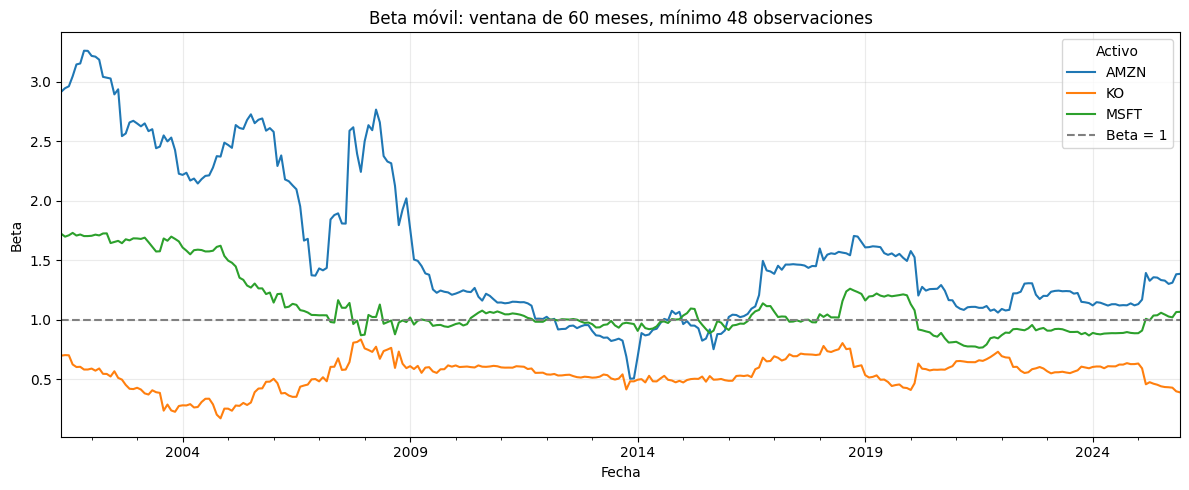

In [ ]:
ax = betas.dropna(how='all').plot(
    figsize=(12, 5),
    linewidth=1.5
)

ax.axhline(1, color='gray', linestyle='--', label='Beta = 1')
ax.set(
    title='Beta móvil: ventana de 60 meses, mínimo 48 observaciones',
    xlabel='Fecha',
    ylabel='Beta'
)
ax.grid(alpha=0.25)
ax.legend(title='Activo')
plt.tight_layout()
plt.show()

# Estimamos las alphas para una venta móvil

In [ ]:
df = tf.download_data(
    domain="Fama-French",
    dataset="Fama/French 3 Factors",
    start_date=START_DATE,
    end_date=END_DATE,
)
df

date,mkt_excess,smb,hml,risk_free
date,f64,f64,f64,f64
1980-01-01,0.055,0.0162,0.0185,0.008
1980-02-01,-0.0123,-0.0186,0.0059,0.0089
1980-03-01,-0.129,-0.067,-0.0096,0.0121
1980-04-01,0.0395,0.0105,0.0103,0.0126
1980-05-01,0.0526,0.0205,0.0038,0.0081
…,…,…,…,…
2025-08-01,0.0184,0.038,0.0437,0.0038
2025-09-01,0.0339,-0.0183,-0.0105,0.0033
2025-10-01,0.0196,-0.0057,-0.0318,0.0037


In [ ]:
df = df.to_pandas()

In [ ]:
df = df.set_index('date')
display(df.head())

,mkt_excess,smb,hml,risk_free
date,,,,
1980-01-01,0.0550,0.0162,0.0185,0.0080
1980-02-01,-0.0123,-0.0186,0.0059,0.0089
1980-03-01,-0.1290,-0.0670,-0.0096,0.0121
1980-04-01,0.0395,0.0105,0.0103,0.0126
1980-05-01,0.0526,0.0205,0.0038,0.0081


In [ ]:
# 1. Convertimos los índices de ambos a PeriodIndex de frecuencia mensual ('M')
y_period = monthly_ret.copy()
y_period.index = pd.PeriodIndex(y_period.index, freq='M')

df_period = df.copy()
df_period.index = pd.PeriodIndex(df_period.index, freq='M')

# 2. Encontramos la intersección de los meses presentes en ambos datasets
common_months = y_period.index.intersection(df_period.index)

# 3. Filtramos ambos para quedarnos únicamente con los meses comunes
y_aligned = y_period.loc[common_months]
df_aligned = df_period.loc[common_months]

# Mostramos que ahora tienen el mismo tamaño y rango de fechas
print(f"Tamaño de y alineado: {y_aligned.shape}")
print(f"Tamaño de df alineado: {df_aligned.shape}")

display(y_aligned.head())
display(df_aligned.head())

Tamaño de y alineado: (343, 4)
Tamaño de df alineado: (343, 4)


Ticker,AMZN,KO,MSFT,^GSPC
1997-06,0.027395,-0.005277,0.018972,0.042535
1997-07,0.440874,0.016409,0.112162,0.075243
1997-08,-0.024207,-0.187398,-0.067194,-0.059183
1997-09,0.618011,0.064788,0.000945,0.051789
1997-10,0.158431,-0.074424,-0.017632,-0.035086


,mkt_excess,smb,hml,risk_free
1997-06,0.0410,0.0119,0.0147,0.0037
1997-07,0.0731,-0.0273,0.0013,0.0043
1997-08,-0.0410,0.0715,0.0113,0.0041
1997-09,0.0534,0.0254,0.0024,0.0044
1997-10,-0.0380,-0.0071,0.0233,0.0042


In [ ]:
y_aligned['rf'] = df_aligned['risk_free']

# Seleccionamos las columnas de activos y del índice.
columnas = y_aligned.columns.drop('rf')

# Restamos el tipo libre de riesgo de cada mes.
excess_returns = y_aligned[columnas].sub(y_aligned['rf'], axis=0)

display(excess_returns.head())

Ticker,AMZN,KO,MSFT,^GSPC
1997-06,0.023695,-0.008977,0.015272,0.038835
1997-07,0.436574,0.012109,0.107862,0.070943
1997-08,-0.028307,-0.191498,-0.071294,-0.063283
1997-09,0.613611,0.060388,-0.003455,0.047389
1997-10,0.154231,-0.078624,-0.021832,-0.039286


In [ ]:
def rolling_alpha_pvalue(monthly_ret, benchmark='^GSPC', activos=ACTIVOS,
                         inicio=START_DATE, fin=END_DATE, ventana=60, min_obs=48):

    if not min_obs <= ventana:
        raise ValueError('Debe cumplirse min_obs <= ventana.')

    datos = excess_returns.copy()

    if not isinstance(datos.index, (pd.DatetimeIndex, pd.PeriodIndex)):
        raise TypeError('El índice debe ser DatetimeIndex o PeriodIndex.')

    datos.index = pd.PeriodIndex(datos.index, freq='M')

    if datos.index.has_duplicates or not datos.columns.is_unique:
        raise ValueError('Los meses y las columnas deben ser únicos.')

    if activos is None:
        activos = [
            c for c in datos.columns
            if c not in [benchmark, 'const']
        ]
    elif isinstance(activos, str):
        activos = [activos]
    else:
        activos = list(activos)

    if benchmark in activos:
        raise ValueError('El benchmark no debe figurar entre los activos.')

    meses = pd.period_range(inicio, fin, freq='M')

    if meses.empty:
        raise ValueError('inicio debe ser anterior o igual a fin.')

    datos = datos.loc[:, [benchmark] + activos].astype(float)
    datos = datos.replace([np.inf, -np.inf], np.nan).reindex(meses)

    alphas = pd.DataFrame(np.nan, index=meses, columns=activos)
    pvalues = pd.DataFrame(np.nan, index=meses, columns=activos)

    alphas.index.name = 'fecha'
    pvalues.index.name = 'fecha'

    for j, fecha in enumerate(meses):

        # Esperamos a disponer de los 60 meses de calendario.
        if j < ventana - 1:
            continue

        muestra = datos.iloc[j - ventana + 1:j + 1]

        for activo in activos:
            pares = muestra[[benchmark, activo]].dropna()

            if len(pares) < min_obs or pares[benchmark].nunique() < 48:
                continue

            regresores = sm.add_constant(
                pares[[benchmark]], has_constant='add'
            )
            modelo = sm.OLS(pares[activo], regresores).fit()

            # Extraemos la constante y su p-value.
            alphas.loc[fecha, activo] = modelo.params['const']
            pvalues.loc[fecha, activo] = modelo.pvalues['const']

    return alphas, pvalues

In [ ]:
alphas, pvalues_alpha =rolling_alpha_pvalue(monthly_ret, benchmark='^GSPC', activos=ACTIVOS,
                         inicio=START_DATE, fin=END_DATE, ventana=60, min_obs=48)

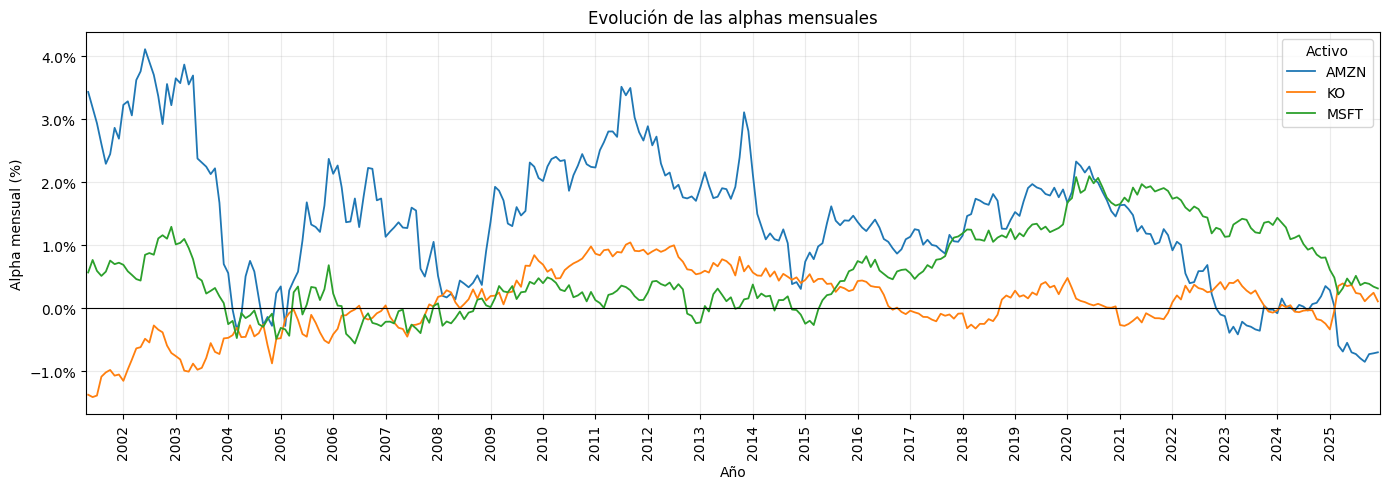

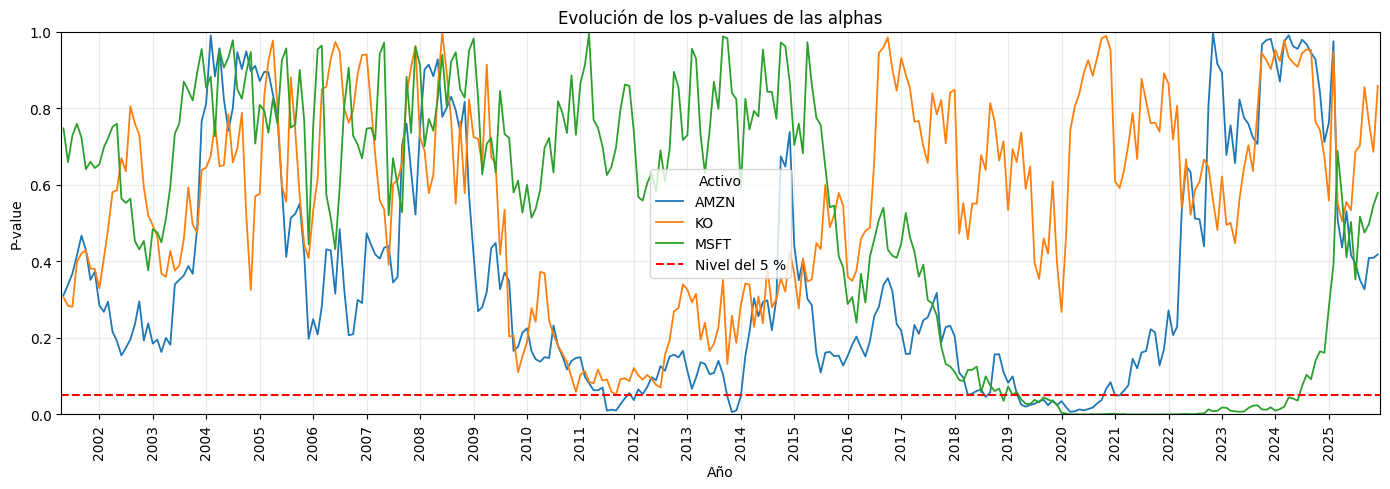

In [ ]:
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

tablas = [alphas, pvalues_alpha]
titulos = [
    'Evolución de las alphas mensuales',
    'Evolución de los p-values de las alphas'
]

for tabla, titulo in zip(tablas, titulos):
    datos = tabla.copy()
    datos.index = pd.PeriodIndex(datos.index, freq='M')
    datos = datos.sort_index()

    disponibles = datos.dropna(how='all')

    if disponibles.empty:
        print(f'{titulo}: no hay estimaciones disponibles.')
        continue

    # Calendario entre la primera y la última estimación.
    meses = pd.period_range(
        disponibles.index.min(),
        disponibles.index.max(),
        freq='M'
    )
    datos = datos.reindex(meses)
    fechas = meses.to_timestamp()

    fig, ax = plt.subplots(figsize=(14, 5))

    for activo in datos.columns:
        if datos[activo].notna().any():
            ax.plot(
                fechas, datos[activo],
                linewidth=1.3, label=activo
            )

    if tabla is alphas:
        ax.axhline(0, color='black', linewidth=0.8)
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
        ax.set_ylabel('Alpha mensual (%)')
    else:
        ax.axhline(
            0.05, color='red', linestyle='--',
            label='Nivel del 5 %'
        )
        ax.set_ylabel('P-value')
        ax.set_ylim(0, 1)

    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.tick_params(axis='x', labelrotation=90)

    # Un pequeño margen también permite mostrar una única observación.
    ax.set_xlim(
        fechas[0] - pd.Timedelta(days=15),
        fechas[-1] + pd.Timedelta(days=15)
    )

    ax.set_title(titulo)
    ax.set_xlabel('Año')
    ax.grid(alpha=0.25)
    ax.legend(title='Activo')

    plt.tight_layout()
    plt.show()

# Sector industrial de SP500, sector aeroespacial y defensa de EE.UU., Sector energía EE.UU.

| Ticker | Qué representa |
|---|---|
| `XLI` | Empresas industriales del S&P 500 |
| `ITA` | Aeroespacial y defensa de EE. UU. |
|`XLE` |  Energía: petróleo, gas y servicios energéticos|

In [ ]:
tickers = ['XLI', 'ITA', 'XLE','^GSPC']
ACTIVOS=['XLI', 'ITA', 'XLE']
precios = yf.download(
    tickers,
    start='1998-01-01',
    end='2026-01-01',
    auto_adjust=True
)['Close']

[*********************100%***********************]  4 of 4 completed


In [ ]:
precios.index = pd.to_datetime(precios.index) # nos aseguramos que index esta en formato fechas
X=precios.resample('ME').last()# selecciona el último disponible de los datos originales
X.head()

Ticker,ITA,XLE,XLI,^GSPC
Date,,,,
1998-01-31,NaN,NaN,NaN,980.280029
1998-02-28,NaN,NaN,NaN,1049.339966
1998-03-31,NaN,NaN,NaN,1101.750000
1998-04-30,NaN,NaN,NaN,1111.750000
1998-05-31,NaN,NaN,NaN,1090.819946


In [ ]:
monthly_ret = np.log(X).diff().dropna()
monthly_ret.head()

Ticker,ITA,XLE,XLI,^GSPC
Date,,,,
2006-06-30,-0.019567,0.025065,-0.001286,0.000087
2006-07-31,0.006971,0.032932,-0.058464,0.005073
2006-08-31,0.003153,-0.052147,0.011225,0.021051
2006-09-30,0.025425,-0.037275,0.037469,0.024269
2006-10-31,0.037786,0.041772,0.027804,0.031022


In [ ]:
betas=rolling_beta(monthly_ret, benchmark='^GSPC', activos=ACTIVOS,
                 inicio=START_DATE, fin=END_DATE, ventana=60, min_obs=48)

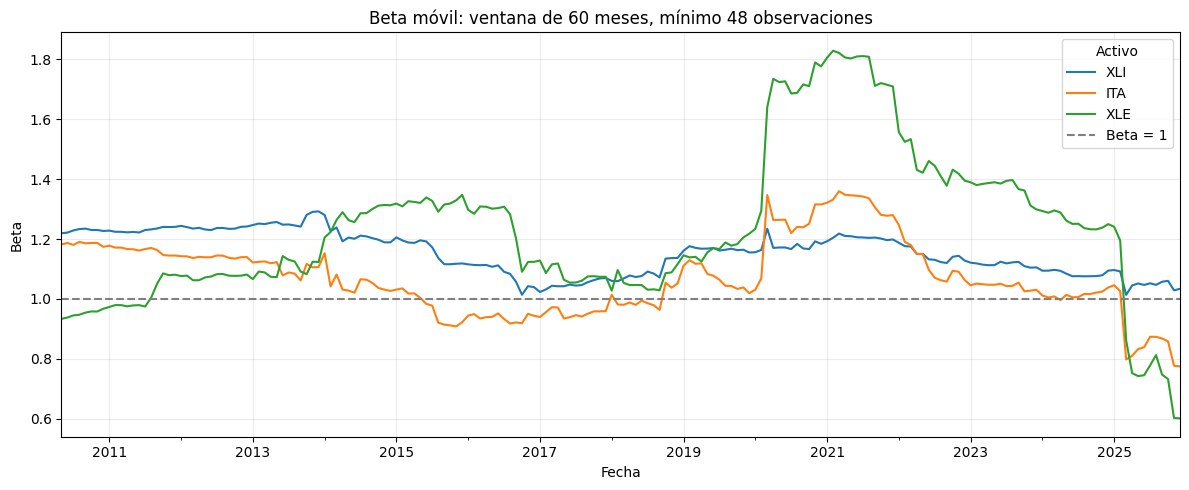

In [ ]:
ax = betas.dropna(how='all').plot(
    figsize=(12, 5),
    linewidth=1.5
)

ax.axhline(1, color='gray', linestyle='--', label='Beta = 1')
ax.set(
    title='Beta móvil: ventana de 60 meses, mínimo 48 observaciones',
    xlabel='Fecha',
    ylabel='Beta'
)
ax.grid(alpha=0.25)
ax.legend(title='Activo')
plt.tight_layout()
plt.show()